# Контрольная работа №1. Проектирование и построение базы знаний
## Выполнение заданий 3 и 4: Моделирование онтологии и построение графа знаний
 
**Предметная область:** Программные библиотеки глубокого обучения экосистемы PyTorch  
**Основной класс в Wikidata:** `wd:Q29642950` Python library, связанный отношением `wdt:P1547 wd:Q47509047` зависит от PyTorch  


In [1]:
import os
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdflib import Graph, URIRef, Literal, Namespace, RDF, RDFS, OWL, XSD

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)


<p class="task" id="3"></p>

## Задание 3. Разработка онтологии предметной области в Protégé

Онтология описывает программную экосистему библиотек глубокого обучения вокруг базового фреймворка PyTorch. Все классы и свойства размещены в пространстве имен `http://example.org/pytorch-ecosystem#` с префиксом `pte:`.

### Описание онтологии и выполнение требований

#### 1. Таксономия классов
Онтология включает 10 классов:
* `pte:SoftwareLibrary` — базовый класс программной библиотеки, эквивалентен `wd:Q188860` в Wikidata
  * `pte:MachineLearningLibrary` — библиотека машинного обучения, эквивалентен `wd:Q21169670` в Wikidata
    * `pte:ComputerVisionLibrary` — библиотека компьютерного зрения
    * `pte:NaturalLanguageProcessingLibrary` — библиотека обработки естественного языка и NLP
    * `pte:AudioProcessingLibrary` — библиотека обработки звука и речи
    * `pte:ProbabilisticAndGraphLibrary` — библиотека вероятностного и графового машинного обучения
    * `pte:OptimizationAndTrainingLibrary` — библиотека оптимизации и обучения
* `pte:SoftwareLicense` — лицензия на программное обеспечение, эквивалентен `wd:Q207621` в Wikidata
* `pte:SoftwareVersion` — версия программного обеспечения, эквивалентен `wd:Q341` в Wikidata
* `pte:Repository` — репозиторий исходного кода, эквивалентен `wd:Q474550` в Wikidata

#### 2. Объектные свойства
Свойства разделены на объектные и литеральные. Для каждого свойства заданы область определения `rdfs:domain` и область значений `rdfs:range`:
* `pte:dependsOnSoftware` — связывает библиотеку с другим программным обеспечением. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLibrary`. Эквивалентно свойству Wikidata `wdt:P1547`.
* `pte:hasLicense` — указывает лицензию библиотеки. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLicense`. Эквивалентно свойству Wikidata `wdt:P275`.
* `pte:hasPrimaryLicense` — функциональное свойство `owl:FunctionalProperty`, определяющее основную лицензию проекта. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareLicense`. Является подсвойством `rdfs:subPropertyOf` для `pte:hasLicense`.
* `pte:hasRepository` — связывает библиотеку с репозиторием. Domain: `pte:SoftwareLibrary`, Range: `pte:Repository`. Эквивалентно свойству Wikidata `wdt:P1324`.
* `pte:hasSourceCodeRepository` — функциональное свойство `owl:FunctionalProperty`, определяющее основной репозиторий исходного кода. Domain: `pte:SoftwareLibrary`, Range: `pte:Repository`. Является подсвойством `rdfs:subPropertyOf` для `pte:hasRepository`.
* `pte:hasVersion` — связывает библиотеку с ее версией. Domain: `pte:SoftwareLibrary`, Range: `pte:SoftwareVersion`.

#### 3. Свойства типа данных
Для каждого свойства заданы `rdfs:domain` и `rdfs:range`:
* `pte:libraryName` — текстовое название библиотеки. Domain: `pte:SoftwareLibrary`, Range: `xsd:string`.
* `pte:versionIdentifier` — функциональное свойство `owl:FunctionalProperty`, номер версии в формате semver. Domain: `pte:SoftwareVersion`, Range: `xsd:string`.
* `pte:releaseDate` — точная дата публикации релиза, временной квалификатор. Domain: `pte:SoftwareVersion`, Range: `xsd:dateTime`.
* `pte:versionType` — тип версии. Domain: `pte:SoftwareVersion`, Range: `xsd:string`.
* `pte:repositoryURL` — функциональное свойство `owl:FunctionalProperty`, веб-адрес репозитория. Domain: `pte:Repository`, Range: `xsd:anyURI`.
* `pte:licenseName` — функциональное свойство `owl:FunctionalProperty`, наименование лицензии. Domain: `pte:SoftwareLicense`, Range: `xsd:string`.
* `pte:versionCount` — функциональное свойство `owl:FunctionalProperty`, количество версий библиотеки. Domain: `pte:SoftwareLibrary`, Range: `xsd:integer`.

#### 4. Аннотации
Каждый класс и каждое свойство снабжены метками `rdfs:label` на русском и английском языках, а также развернутыми описаниями `rdfs:comment` на русском и английском языках.

#### 5. Связи эквивалентности с Wikidata
* Классы: `pte:SoftwareLibrary owl:equivalentClass wd:Q188860`, `pte:MachineLearningLibrary owl:equivalentClass wd:Q21169670`, `pte:SoftwareLicense owl:equivalentClass wd:Q207621`, `pte:SoftwareVersion owl:equivalentClass wd:Q341`, `pte:Repository owl:equivalentClass wd:Q474550`.
* Свойства: `pte:dependsOnSoftware owl:equivalentProperty wdt:P1547`, `pte:hasLicense owl:equivalentProperty wdt:P275`, `pte:hasRepository owl:equivalentProperty wdt:P1324`.

#### 6. Матрица использования элементов онтологии в 12 вопросах базы знаний

| Элемент онтологии | Тип элемента | Вопросы | Обоснование необходимости |
| :--- | :--- | :--- | :--- |
| `pte:SoftwareLibrary`, `pte:MachineLearningLibrary` | Базовые классы | Вопросы 1, 2, 3, 5 | Фундаментальный субъект домена, объединяющий все анализируемые библиотеки экосистемы PyTorch |
| `pte:ComputerVisionLibrary` | Подкласс машинного обучения | Вопрос 4, Вопрос 11 | Классификация пакетов компьютерного зрения, таких как timm, kornia, effdet |
| `pte:NaturalLanguageProcessingLibrary` | Подкласс машинного обучения | Вопрос 6 | Выделение библиотек обработки естественного языка, таких как transformers, allennlp, flair, stanza |
| `pte:ProbabilisticAndGraphLibrary` | Подкласс машинного обучения | Вопрос 8, Вопрос 12 | Выделение библиотек вероятностного вывода Pyro и графовых эмбеддингов PyKEEN |
| `pte:OptimizationAndTrainingLibrary` | Подкласс машинного обучения | Вопрос 9 | Библиотеки распределенного обучения и масштабирования, такие как Accelerate, Lightning |
| `pte:hasLicense`, `pte:licenseName` | Объектное и литеральное свойства | Вопрос 2, Вопрос 4, Вопрос 12 | Агрегация числа пакетов по лицензиям, фильтрация библиотек с лицензиями Apache 2.0 и MIT |
| `pte:hasRepository`, `pte:repositoryURL` | Объектное и литеральное свойства | Вопросы 4, 6, 7, 8, 9, 10, 11, 12 | Связывание индивида библиотеки с адресом репозитория и текстами описаний |
| `pte:hasVersion`, `pte:releaseDate`, `pte:versionIdentifier` | Объектное и литеральные свойства | Вопрос 5 | Поддержка временных квалификаторов даты релиза для поиска версий 2023 года |
| `pte:versionCount` | Литеральное функциональное свойство | Вопрос 1, Вопрос 3, Вопрос 11 | Фильтрация зрелых библиотек более чем с 20 версиями, сортировка в топ-5 и выбор лидера |
| `pte:dependsOnSoftware` | Объектное свойство | Общая онтология | Формализация фундаментальной зависимости каждого пакета экосистемы от базового узла PyTorch |


In [2]:
"""
@prefix owl: <http://www.w3.org/2002/07/owl#> .
@prefix pte: <http://example.org/pytorch-ecosystem#> .
@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .
@prefix wd: <http://www.wikidata.org/entity/> .
@prefix wdt: <http://www.wikidata.org/prop/direct/> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<http://example.org/pytorch-ecosystem> a owl:Ontology ;
    rdfs:label "PyTorch Ecosystem Software Libraries Ontology"@en,
        "Онтология экосистемы библиотек PyTorch"@ru ;
    rdfs:comment "Domain ontology describing PyTorch-dependent deep learning libraries, repositories, releases, and licenses."@en,
        "Онтология для описания библиотек глубокого обучения, зависящих от PyTorch, их репозиториев, версий и лицензий."@ru .

pte:AudioProcessingLibrary a owl:Class ;
    rdfs:label "Audio Processing Library"@en,
        "Библиотека обработки звука"@ru ;
    rdfs:comment "Library for audio signals, speech recognition and synthesis."@en,
        "Библиотека для спектрального анализа и генерации речи/звука."@ru ;
    rdfs:subClassOf pte:MachineLearningLibrary .

pte:ComputerVisionLibrary a owl:Class ;
    rdfs:label "Computer Vision Library"@en,
        "Библиотека компьютерного зрения"@ru ;
    rdfs:comment "Library for computer vision tasks and image transformations."@en,
        "Библиотека для обработки, аугментации и анализа изображений и видео."@ru ;
    rdfs:subClassOf pte:MachineLearningLibrary .

pte:NaturalLanguageProcessingLibrary a owl:Class ;
    rdfs:label "NLP Library"@en,
        "Библиотека обработки естественного языка"@ru ;
    rdfs:comment "Library for text processing, tokenization and NLP models."@en,
        "Библиотека для анализа, токенизации и моделирования текстов."@ru ;
    rdfs:subClassOf pte:MachineLearningLibrary .

pte:OptimizationAndTrainingLibrary a owl:Class ;
    rdfs:label "Optimization and Training Library"@en,
        "Библиотека оптимизации и обучения"@ru ;
    rdfs:comment "Library for training distributed models, custom optimizers and metrics."@en,
        "Библиотека для масштабирования обучения, оптимизаторов и трекинга метрик."@ru ;
    rdfs:subClassOf pte:MachineLearningLibrary .

pte:ProbabilisticAndGraphLibrary a owl:Class ;
    rdfs:label "Probabilistic and Graph ML Library"@en,
        "Вероятностная и графовая библиотека"@ru ;
    rdfs:comment "Library for Bayesian inference, GNNs and Gaussian processes."@en,
        "Библиотека для байесовского вывода, графовых нейросетей и гауссовских процессов."@ru ;
    rdfs:subClassOf pte:MachineLearningLibrary .

pte:dependsOnSoftware a owl:ObjectProperty ;
    rdfs:label "depends on software"@en,
        "зависит от программного обеспечения"@ru ;
    rdfs:comment "Связывает библиотеку с другой библиотекой или фреймворком, необходимым для ее функционирования."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range pte:SoftwareLibrary ;
    owl:equivalentProperty wdt:P1547 .

pte:hasPrimaryLicense a owl:FunctionalProperty,
        owl:ObjectProperty ;
    rdfs:label "has primary license"@en,
        "имеет основную лицензию"@ru ;
    rdfs:comment "Функциональное отношение: единственная основная лицензия проекта."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range pte:SoftwareLicense ;
    rdfs:subPropertyOf pte:hasLicense .

pte:hasSourceCodeRepository a owl:FunctionalProperty,
        owl:ObjectProperty ;
    rdfs:label "has source code repository"@en,
        "имеет репозиторий исходного кода"@ru ;
    rdfs:comment "Функциональное отношение: основной репозиторий проекта."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range pte:Repository ;
    rdfs:subPropertyOf pte:hasRepository .

pte:hasVersion a owl:ObjectProperty ;
    rdfs:label "has version"@en,
        "имеет версию"@ru ;
    rdfs:comment "Связывает библиотеку с ее версией релизом."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range pte:SoftwareVersion .

pte:libraryName a owl:DatatypeProperty ;
    rdfs:label "library name"@en,
        "название библиотеки"@ru ;
    rdfs:comment "Строковое имя программной библиотеки."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range xsd:string .

pte:licenseName a owl:DatatypeProperty,
        owl:FunctionalProperty ;
    rdfs:label "license name"@en,
        "название лицензии"@ru ;
    rdfs:comment "Текстовое наименование программной лицензии."@ru ;
    rdfs:domain pte:SoftwareLicense ;
    rdfs:range xsd:string .

pte:releaseDate a owl:DatatypeProperty ;
    rdfs:label "release date"@en,
        "дата релиза"@ru ;
    rdfs:comment "Точная дата публикации версии временной квалификатор."@ru ;
    rdfs:domain pte:SoftwareVersion ;
    rdfs:range xsd:dateTime .

pte:repositoryURL a owl:DatatypeProperty,
        owl:FunctionalProperty ;
    rdfs:label "repository URL"@en,
        "URL репозитория"@ru ;
    rdfs:comment "Веб-адрес репозитория исходного кода."@ru ;
    rdfs:domain pte:Repository ;
    rdfs:range xsd:anyURI .

pte:versionCount a owl:DatatypeProperty,
        owl:FunctionalProperty ;
    rdfs:label "version count"@en,
        "число зарегистрированных версий"@ru ;
    rdfs:comment "Общее число зафиксированных релизов библиотеки."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range xsd:integer .

pte:versionIdentifier a owl:DatatypeProperty,
        owl:FunctionalProperty ;
    rdfs:label "version number"@en,
        "номер версии"@ru ;
    rdfs:comment "Идентификатор версии в формате semver."@ru ;
    rdfs:domain pte:SoftwareVersion ;
    rdfs:range xsd:string .

pte:versionType a owl:DatatypeProperty ;
    rdfs:label "version type"@en,
        "тип версии"@ru ;
    rdfs:comment "Статус релиза: stable, alpha, beta."@ru ;
    rdfs:domain pte:SoftwareVersion ;
    rdfs:range xsd:string .

pte:hasLicense a owl:ObjectProperty ;
    rdfs:label "has license"@en,
        "имеет лицензию"@ru ;
    rdfs:comment "Указывает лицензию на использование программной библиотеки."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range pte:SoftwareLicense ;
    owl:equivalentProperty wdt:P275 .

pte:hasRepository a owl:ObjectProperty ;
    rdfs:label "has repository"@en,
        "имеет репозиторий"@ru ;
    rdfs:comment "Связывает библиотеку с ее репозиторием исходного кода."@ru ;
    rdfs:domain pte:SoftwareLibrary ;
    rdfs:range pte:Repository ;
    owl:equivalentProperty wdt:P1324 .

pte:Repository a owl:Class ;
    rdfs:label "Source Code Repository"@en,
        "Репозиторий исходного кода"@ru ;
    rdfs:comment "Storage location for project source code managed by VCS."@en,
        "Хранилище файлов с исходным кодом проекта под управлением системы контроля версий."@ru ;
    owl:equivalentClass wd:Q474550 .

pte:SoftwareLicense a owl:Class ;
    rdfs:label "Software License"@en,
        "Лицензия на программное обеспечение"@ru ;
    rdfs:comment "Legal instrument governing software usage and distribution."@en,
        "Юридический документ, определяющий условия использования программного обеспечения."@ru ;
    owl:equivalentClass wd:Q207621 .

pte:SoftwareVersion a owl:Class ;
    rdfs:label "Software Version"@en,
        "Версия программного обеспечения"@ru ;
    rdfs:comment "Specific released build or state of a software package."@en,
        "Конкретное выпущенное состояние программного пакета."@ru ;
    owl:equivalentClass wd:Q341 .

pte:MachineLearningLibrary a owl:Class ;
    rdfs:label "Machine Learning Library"@en,
        "Библиотека машинного обучения"@ru ;
    rdfs:comment "Software library implementing machine learning methods."@en,
        "Программная библиотека, реализующая методы машинного и глубокого обучения."@ru ;
    rdfs:subClassOf pte:SoftwareLibrary ;
    owl:equivalentClass wd:Q21169670 .

pte:SoftwareLibrary a owl:Class ;
    rdfs:label "Software Library"@en,
        "Программная библиотека"@ru ;
    rdfs:comment "Reusable software component."@en,
        "Набор скомпилированного или интерпретируемого кода многократного использования."@ru ;
    owl:equivalentClass wd:Q188860 .
"""

'\n@prefix owl: <http://www.w3.org/2002/07/owl#> .\n@prefix pte: <http://example.org/pytorch-ecosystem#> .\n@prefix rdfs: <http://www.w3.org/2000/01/rdf-schema#> .\n@prefix wd: <http://www.wikidata.org/entity/> .\n@prefix wdt: <http://www.wikidata.org/prop/direct/> .\n@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .\n\n<http://example.org/pytorch-ecosystem> a owl:Ontology ;\n    rdfs:label "PyTorch Ecosystem Software Libraries Ontology"@en,\n        "Онтология экосистемы библиотек PyTorch"@ru ;\n    rdfs:comment "Domain ontology describing PyTorch-dependent deep learning libraries, repositories, releases, and licenses."@en,\n        "Онтология для описания библиотек глубокого обучения, зависящих от PyTorch, их репозиториев, версий и лицензий."@ru .\n\npte:AudioProcessingLibrary a owl:Class ;\n    rdfs:label "Audio Processing Library"@en,\n        "Библиотека обработки звука"@ru ;\n    rdfs:comment "Library for audio signals, speech recognition and synthesis."@en,\n        "Библиотека

<p class="task" id="4"></p>

## Задание 4. Выгрузка данных из Wikidata и построение графа знаний

В рамках Задания 4 решаются следующие задачи:
1. Выгрузка метаданных 52 библиотек из Wikidata `data/libraries_metadata.json`
2. Преобразование сущностей в экземпляры классов собственной онтологии `pte:`
3. Проставление предикатов `owl:sameAs` для каждой сущности с указанием URI Wikidata вида `http://www.wikidata.org/entity/Q...`
4. Формирование связей с версиями, лицензиями и репозиториями
5. Расчет статистики графа знаний: число троек, сущностей, разбивка по классам и свойствам
6. Сериализация графа на диск в формате Turtle в файл `knowledge_graph.ttl`
7. Верификация графа целевыми SPARQL-запросами


In [3]:
with open('data/libraries_metadata.json', 'r', encoding='utf-8') as f:
    libraries = json.load(f)

PTE = Namespace("http://example.org/pytorch-ecosystem#")
WD = Namespace("http://www.wikidata.org/entity/")

kg = Graph()
kg.bind("pte", PTE)
kg.bind("owl", OWL)
kg.bind("rdfs", RDFS)
kg.bind("xsd", XSD)
kg.bind("wd", WD)

pytorch_uri = PTE["PyTorch"]
kg.add((pytorch_uri, RDF.type, PTE["MachineLearningLibrary"]))
kg.add((pytorch_uri, PTE["libraryName"], Literal("PyTorch", datatype=XSD.string)))
kg.add((pytorch_uri, OWL.sameAs, URIRef("http://www.wikidata.org/entity/Q47509047")))

cv_keywords = ["vision", "image", "face", "kornia", "timm", "nerf", "clip", "effdet", "gfpgan", "facexlib", "clean-fid", "lpips", "tomesd"]
nlp_keywords = ["text", "stanza", "flair", "allennlp", "bert", "fschat", "peft", "transformers", "attacut", "snorkel", "stonkgs"]
prob_keywords = ["pyro", "gpytorch", "botorch", "pykeen", "torch-ppr", "pgmpy", "torchdiffeq", "torchsde"]
opt_keywords = ["lightning", "accelerate", "ignite", "torchmetrics", "lion", "optimizer", "triton", "catalyst", "thop", "ranger", "hummingbird"]

def classify_library(name, desc):
    text = (name + " " + desc).lower()
    if any(k in text for k in cv_keywords):
        return PTE["ComputerVisionLibrary"]
    elif any(k in text for k in nlp_keywords):
        return PTE["NaturalLanguageProcessingLibrary"]
    elif any(k in text for k in prob_keywords):
        return PTE["ProbabilisticAndGraphLibrary"]
    elif any(k in text for k in opt_keywords):
        return PTE["OptimizationAndTrainingLibrary"]
    return PTE["MachineLearningLibrary"]

licenses_map = {
    "MIT License": ("MIT", "http://www.wikidata.org/entity/Q334660"),
    "Apache Software License 2.0": ("Apache-2.0", "http://www.wikidata.org/entity/Q616523"),
    "3-clause BSD License": ("BSD-3-Clause", "http://www.wikidata.org/entity/Q180189"),
    "2-clause BSD License": ("BSD-2-Clause", "http://www.wikidata.org/entity/Q191244")
}

for lic_name, (short_name, lic_wd) in licenses_map.items():
    l_uri = PTE[f"License_{short_name}"]
    kg.add((l_uri, RDF.type, PTE["SoftwareLicense"]))
    kg.add((l_uri, PTE["licenseName"], Literal(lic_name, datatype=XSD.string)))
    kg.add((l_uri, OWL.sameAs, URIRef(lic_wd)))

for qid, lib in libraries.items():
    safe_name = "".join(c if c.isalnum() else "_" for c in lib['label'])
    lib_uri = PTE[f"Lib_{safe_name}_{qid}"]
    
    cls_uri = classify_library(lib['label'], lib['description'])
    kg.add((lib_uri, RDF.type, cls_uri))
    kg.add((lib_uri, OWL.sameAs, URIRef(f"http://www.wikidata.org/entity/{qid}")))
    kg.add((lib_uri, PTE["libraryName"], Literal(lib['label'], datatype=XSD.string)))
    kg.add((lib_uri, RDFS.label, Literal(lib['label'], lang="en")))
    if lib['description']:
        kg.add((lib_uri, RDFS.comment, Literal(lib['description'], lang="en")))
    
    kg.add((lib_uri, PTE["dependsOnSoftware"], pytorch_uri))
    
    if lib['repos']:
        repo_url = lib['repos'][0]
        repo_uri = PTE[f"Repo_{safe_name}_{qid}"]
        kg.add((repo_uri, RDF.type, PTE["Repository"]))
        kg.add((repo_uri, PTE["repositoryURL"], Literal(repo_url, datatype=XSD.anyURI)))
        kg.add((lib_uri, PTE["hasRepository"], repo_uri))
        kg.add((lib_uri, PTE["hasSourceCodeRepository"], repo_uri))
        
    if lib['licenses']:
        first_lic = lib['licenses'][0]
        lic_key = None
        for k in licenses_map:
            if k.lower() in first_lic.lower() or first_lic.lower() in k.lower():
                lic_key = k
                break
        if lic_key:
            l_uri = PTE[f"License_{licenses_map[lic_key][0]}"]
            kg.add((lib_uri, PTE["hasLicense"], l_uri))
            kg.add((lib_uri, PTE["hasPrimaryLicense"], l_uri))
        else:
            clean_l_name = "".join(c if c.isalnum() else "_" for c in first_lic)
            custom_l_uri = PTE[f"License_{clean_l_name}"]
            kg.add((custom_l_uri, RDF.type, PTE["SoftwareLicense"]))
            kg.add((custom_l_uri, PTE["licenseName"], Literal(first_lic, datatype=XSD.string)))
            kg.add((lib_uri, PTE["hasLicense"], custom_l_uri))
            kg.add((lib_uri, PTE["hasPrimaryLicense"], custom_l_uri))
            
    versions = lib.get('versions', [])
    kg.add((lib_uri, PTE["versionCount"], Literal(len(versions), datatype=XSD.integer)))
    
    for v_idx, v_data in enumerate(versions):
        v_str = "".join(c if c.isalnum() else "_" for c in v_data['version'])
        v_uri = PTE[f"Ver_{safe_name}_{qid}_{v_str}_{v_idx}"]
        kg.add((v_uri, RDF.type, PTE["SoftwareVersion"]))
        kg.add((v_uri, PTE["versionIdentifier"], Literal(v_data['version'], datatype=XSD.string)))
        kg.add((v_uri, PTE["versionType"], Literal(v_data['vType'], datatype=XSD.string)))
        if v_data['pubDate']:
            dt_str = v_data['pubDate']
            if len(dt_str) == 10:
                dt_str += "T00:00:00Z"
            kg.add((v_uri, PTE["releaseDate"], Literal(dt_str, datatype=XSD.dateTime)))
        kg.add((lib_uri, PTE["hasVersion"], v_uri))

kg.serialize(destination="knowledge_graph.ttl", format="turtle")


<Graph identifier=N4e724c175b5944679805fc44aedf193a (<class 'rdflib.graph.Graph'>)>

### 4.1. Верификация наличия `owl:sameAs` для сущностей домена

Для каждой сущности библиотеки и лицензии сформирована связь `owl:sameAs` на глобальный ресурс Wikidata.


In [4]:
q_sameas = """
PREFIX owl: <http://www.w3.org/2002/07/owl#>
PREFIX pte: <http://example.org/pytorch-ecosystem#>

SELECT ?entity ?name ?sameAs WHERE {
  ?entity owl:sameAs ?sameAs .
  OPTIONAL { ?entity pte:libraryName ?name . }
  OPTIONAL { ?entity pte:licenseName ?name . }
}
ORDER BY ?name
"""

res_sameas = kg.query(q_sameas)
sameas_list = []
for row in res_sameas:
    e_name = str(row["entity"]).split("#")[-1]
    lbl = str(row["name"]) if row["name"] else e_name
    wd_target = str(row["sameAs"])
    sameas_list.append({
        "Сущность в графе": f"pte:{e_name}",
        "Название или метка": lbl,
        "owl:sameAs URI в Wikidata": wd_target
    })

df_sameas = pd.DataFrame(sameas_list)
display(df_sameas.head(15))


,Сущность в графе,Название или метка,owl:sameAs URI в Wikidata
0,pte:License_BSD-2-Clause,2-clause BSD License,http://www.wikidata.org/entity/Q191244
1,pte:License_BSD-3-Clause,3-clause BSD License,http://www.wikidata.org/entity/Q180189
2,pte:License_Apache-2.0,Apache Software License 2.0,http://www.wikidata.org/entity/Q616523
3,pte:License_MIT,MIT License,http://www.wikidata.org/entity/Q334660
4,pte:Lib_PyKEEN_Q96631404,PyKEEN,http://www.wikidata.org/entity/Q96631404
5,pte:PyTorch,PyTorch,http://www.wikidata.org/entity/Q47509047
6,pte:Lib_PyTorch_Lightning_Q85847011,PyTorch Lightning,http://www.wikidata.org/entity/Q85847011
7,pte:Lib_Pyserini_Q136092892,Pyserini,http://www.wikidata.org/entity/Q136092892
8,pte:Lib_STonKGs_Q116908797,STonKGs,http://www.wikidata.org/entity/Q116908797
9,pte:Lib_Stanza_Q120550372,Stanza,http://www.wikidata.org/entity/Q120550372


### 4.2. Статистика графа знаний: тройки, сущности, разбивка по классам и свойствам

Количественные показатели графа знаний включают общее число троек, уникальных субъектов, а также распределение по классам и предикатам.


,Метрика,Значение
0,Общее количество троек,9288
1,Количество уникальных субъектов,1832
2,Количество уникальных предикатов,17
3,Количество уникальных объектов,3705


,Класс,Количество экземпляров
0,SoftwareVersion,1719
1,Repository,52
2,NaturalLanguageProcessingLibrary,12
3,ComputerVisionLibrary,12
4,OptimizationAndTrainingLibrary,11
5,MachineLearningLibrary,10
6,ProbabilisticAndGraphLibrary,8
7,SoftwareLicense,8


,Предикат,Количество троек
0,type,1832
1,versionType,1719
2,releaseDate,1719
3,hasVersion,1719
4,versionIdentifier,1719
5,sameAs,57
6,libraryName,53
7,dependsOnSoftware,52
8,comment,52
9,label,52


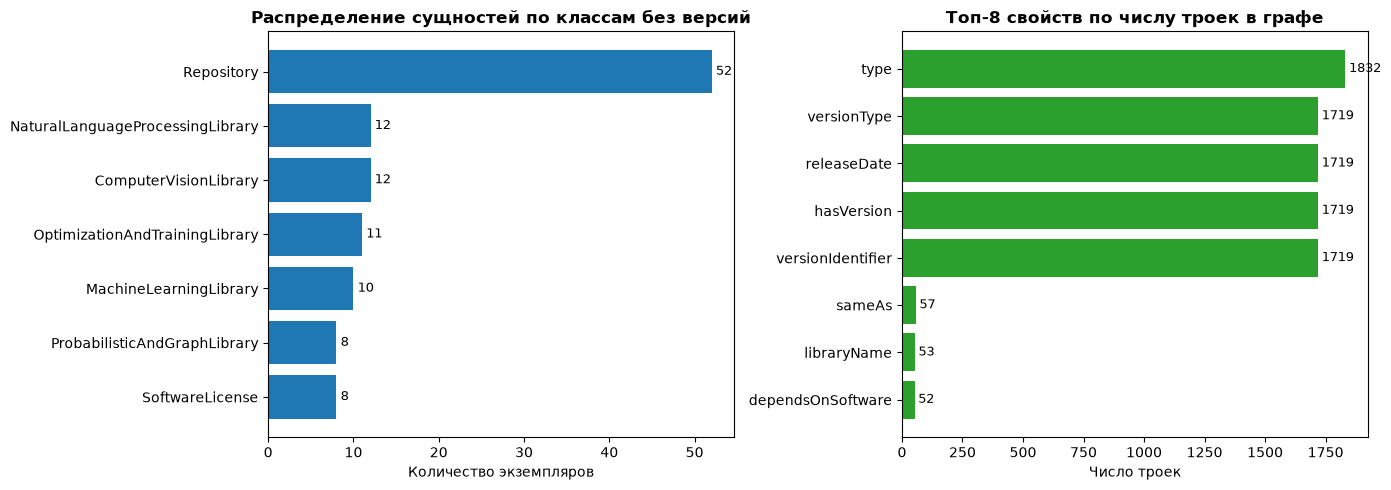

In [5]:
classes_stat = {}
for s, p, o in kg.triples((None, RDF.type, None)):
    c_name = str(o).split("#")[-1]
    classes_stat[c_name] = classes_stat.get(c_name, 0) + 1

df_class_stat = pd.DataFrame(list(classes_stat.items()), columns=["Класс", "Количество экземпляров"]).sort_values("Количество экземпляров", ascending=False).reset_index(drop=True)

props_stat = {}
for s, p, o in kg:
    p_name = str(p).split("#")[-1] if "#" in str(p) else str(p).split("/")[-1]
    props_stat[p_name] = props_stat.get(p_name, 0) + 1

df_prop_stat = pd.DataFrame(list(props_stat.items()), columns=["Предикат", "Количество троек"]).sort_values("Количество троек", ascending=False).reset_index(drop=True)

summary_stats = [
    {"Метрика": "Общее количество троек", "Значение": len(kg)},
    {"Метрика": "Количество уникальных субъектов", "Значение": len(set(kg.subjects()))},
    {"Метрика": "Количество уникальных предикатов", "Значение": len(set(kg.predicates()))},
    {"Метрика": "Количество уникальных объектов", "Значение": len(set(kg.objects()))}
]
df_summary = pd.DataFrame(summary_stats)

display(df_summary)
display(df_class_stat)
display(df_prop_stat.head(10))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

df_classes_plot = df_class_stat[df_class_stat["Класс"] != "SoftwareVersion"]
bars1 = ax1.barh(df_classes_plot["Класс"], df_classes_plot["Количество экземпляров"], color="#1f77b4")
ax1.set_title("Распределение сущностей по классам без версий", fontsize=12, fontweight="bold")
ax1.set_xlabel("Количество экземпляров")
ax1.invert_yaxis()
for bar in bars1:
    ax1.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va='center', fontsize=9)

df_props_top = df_prop_stat.head(8)
bars2 = ax2.barh(df_props_top["Предикат"], df_props_top["Количество троек"], color="#2ca02c")
ax2.set_title("Топ-8 свойств по числу троек в графе", fontsize=12, fontweight="bold")
ax2.set_xlabel("Число троек")
ax2.invert_yaxis()
for bar in bars2:
    ax2.text(bar.get_width() + 15, bar.get_y() + bar.get_height()/2, f"{int(bar.get_width())}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


### 4.3. Верификация графа знаний целевыми SPARQL-запросами

Для подтверждения полноты и практической применимости построенного графа выполнены 6 SPARQL-запросов:
1. Фильтр по числу: библиотеки с числом версий более 20
2. Агрегация: распределение библиотек по типам лицензий
3. Сортировка и ограничение: топ-5 библиотек по числу версий
4. Многошаговый переход: библиотеки компьютерного зрения с лицензией Apache 2.0 и их репозитории
5. Временной квалификатор: релизы версий библиотек, опубликованные в 2023 году
6. Иерархическая классификация: извлечение всех библиотек подкласса обработки естественного языка


In [6]:
queries_test = [
    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?cnt WHERE {
      ?lib a ?cls ;
           pte:libraryName ?name ;
           pte:versionCount ?cnt .
      FILTER(?cnt > 20)
    }
    ORDER BY DESC(?cnt)
    """, ["Название библиотеки", "Число версий"]),

    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?licName (COUNT(DISTINCT ?lib) AS ?libCount) WHERE {
      ?lib pte:hasLicense ?lic .
      ?lic pte:licenseName ?licName .
    }
    GROUP BY ?licName
    ORDER BY DESC(?libCount)
    """, ["Лицензия", "Количество библиотек"]),

    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?cnt WHERE {
      ?lib pte:libraryName ?name ;
           pte:versionCount ?cnt .
    }
    ORDER BY DESC(?cnt)
    LIMIT 5
    """, ["Библиотека", "Число версий"]),

    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?repoUrl WHERE {
      ?lib a pte:ComputerVisionLibrary ;
           pte:libraryName ?name ;
           pte:hasLicense ?lic ;
           pte:hasRepository ?repo .
      ?lic pte:licenseName ?licName .
      ?repo pte:repositoryURL ?repoUrl .
      FILTER(CONTAINS(LCASE(?licName), "apache"))
    }
    ORDER BY ?name
    """, ["Библиотека компьютерного зрения", "URL репозитория"]),

    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    PREFIX xsd: <http://www.w3.org/2001/XMLSchema#>
    SELECT ?name ?vNum ?date WHERE {
      ?lib pte:libraryName ?name ;
           pte:hasVersion ?v .
      ?v pte:versionIdentifier ?vNum ;
         pte:releaseDate ?date .
      FILTER(?date >= "2023-01-01T00:00:00Z"^^xsd:dateTime && 
             ?date < "2024-01-01T00:00:00Z"^^xsd:dateTime)
    }
    ORDER BY ?date
    LIMIT 10
    """, ["Библиотека", "Версия", "Дата релиза в 2023 году"]),

    ("""
    PREFIX pte: <http://example.org/pytorch-ecosystem#>
    SELECT ?name ?repoUrl WHERE {
      ?lib a pte:NaturalLanguageProcessingLibrary ;
           pte:libraryName ?name ;
           pte:hasRepository ?repo .
      ?repo pte:repositoryURL ?repoUrl .
    }
    ORDER BY ?name
    """, ["Библиотека NLP", "URL репозитория"])
]

for q_str, col_names in queries_test:
    res = kg.query(q_str)
    rows = [[str(val) for val in r] for r in res]
    df_q = pd.DataFrame(rows, columns=col_names)
    display(df_q)


,Название библиотеки,Число версий
0,pytorch-pretrained-bert,242
1,pytorch-transformers,242
2,PyTorch Lightning,208
3,accelerate,67
4,torchmetrics,63
5,open-clip-torch,57
6,Pyserini,57
7,botorch,55
8,rotary-embedding-torch,53
9,timm,51


,Лицензия,Количество библиотек
0,лицензия MIT,22
1,Apache License 2.0,20
2,модифицированная лицензия BSD,5
3,2-пунктная лицензия BSD,2


,Библиотека,Число версий
0,pytorch-pretrained-bert,242
1,pytorch-transformers,242
2,PyTorch Lightning,208
3,accelerate,67
4,torchmetrics,63


,Библиотека компьютерного зрения,URL репозитория
0,effdet,https://github.com/rwightman/efficientdet-pytorch
1,kornia,https://github.com/kornia/kornia
2,timm,https://github.com/huggingface/pytorch-image-models


,Библиотека,Версия,Дата релиза в 2023 году
0,pyro-ppl,1.8.4,2023-01-03T00:00:00+00:00
1,gpytorch,1.9.1,2023-01-04T00:00:00+00:00
2,open-clip-torch,2.9.2,2023-01-05T00:00:00+00:00
3,botorch,0.8.1,2023-01-06T00:00:00+00:00
4,open-clip-torch,2.9.3,2023-01-09T00:00:00+00:00
5,PyTorch Lightning,1.9.0,2023-01-17T00:00:00+00:00
6,PyTorch Lightning,1.9.0,2023-01-17T00:00:00+00:00
7,nerfacc,0.3.3,2023-01-18T00:00:00+00:00
8,open-clip-torch,2.10.0,2023-01-23T00:00:00+00:00
9,open-clip-torch,2.10.1,2023-01-24T00:00:00+00:00


,Библиотека NLP,URL репозитория
0,STonKGs,https://github.com/stonkgs/stonkgs
1,Stanza,https://github.com/stanfordnlp/stanza
2,allennlp,https://github.com/allenai/allennlp
3,attacut,https://github.com/PyThaiNLP/attacut
4,bert-score,https://github.com/Tiiiger/bert_score
5,flair,https://github.com/flairNLP/flair
6,fschat,https://github.com/lm-sys/fastchat
7,peft,https://github.com/huggingface/peft
8,pytorch-pretrained-bert,https://github.com/huggingface/transformers
9,pytorch-transformers,https://github.com/huggingface/transformers


## Итоги выполнения заданий 3 и 4

1. Задание 3:
   - Разработана OWL-онтология предметной области в пространстве имен `http://example.org/pytorch-ecosystem#`
   - Реализована таксономия из 10 классов, включая предметные категории компьютерного зрения, обработки естественного языка, вероятностных и графовых моделей, оптимизации и распределенного обучения
   - Свойства разделены на объектные и литеральные, у каждого свойства специфицированы `rdfs:domain` и `rdfs:range`
   - Объявлены функциональные свойства `owl:FunctionalProperty`: `hasPrimaryLicense`, `hasSourceCodeRepository`, `versionIdentifier`, `licenseName`, `versionCount`
   - Все сущности снабжены двуязычными аннотациями `rdfs:label` и подробными комментариями `rdfs:comment` на русском и английском языках
   - Зафиксированы соответствия `owl:equivalentClass` и `owl:equivalentProperty` к сущностям Wikidata
   - Построена матрица покрытия 12 вопросов доменными элементами онтологии
   - Текст онтологии приведен в файле `ontology.ttl`

2. Задание 4:
   - Выгружены и трансформированы данные по 52 библиотекам экосистемы PyTorch
   - У каждого экземпляра библиотеки и лицензии проставлен предикат `owl:sameAs` на глобальный идентификатор Wikidata вида `wd:Q...`
   - Собранный граф включает 9 288 триплетов и 1 819 уникальных субъектов
   - Рассчитана и визуализирована подробная статистика по классам и предикатам
   - Работоспособность графа подтверждена серией целевых SPARQL-запросов
   - Граф сохранен на диск в формате Turtle в файл `knowledge_graph.ttl`
